# Quantum-Secure Fraud Detection System
## Layer 1 — Classical and Quantum Fraud Detection Research

This notebook is the reproducible research record for Layer 1 of the QSFD project. It loads **real, previously
computed artifacts** from this repository (CSV/JSON/NPZ result files, saved model metadata) — it does not
retrain expensive models inline, and it does not hand-type any result value that has a corresponding saved
artifact. Where a figure or table is shown, the cell above it states which file it was loaded from.

**Scientific standard followed throughout**: every claim is labeled by evidence strength. A finding is called
*statistically supported* only where a specific test (bootstrap CI, Wilcoxon, permutation) backs it. Negative
results are reported as plainly as positive ones. No claim of "quantum advantage" or "quantum supremacy" is made
anywhere in this notebook.

## 1. Research Objective

Layer 1 answers two separate questions:

1. **Predictive question**: what is the strongest fraud-detection model achievable with classical ML, and does
   any quantum or quantum-inclusive architecture measurably improve on it?
2. **Quantum-architecture question**: independent of (1), does a specific, literature-motivated change to a
   quantum circuit's design (observable locality) measurably change that circuit's own standalone performance
   and trainability?

These are evaluated separately throughout this notebook, and their answers turn out to differ — Section 37
states the resulting Layer 1 conclusion precisely.

## 1b. Research Motivation, Hypotheses, and Experimental Philosophy

The central research question this notebook investigates is not "does quantum beat classical?" in isolation, but
the broader question: **where does quantum model design provide measurable utility, where does it fail to, and
what is the boundary of any observed effect?** The experimental philosophy followed throughout is:

```
QUESTION -> HYPOTHESIS -> CONTROLLED EXPERIMENT -> RESULT -> STRONGER CONTROL -> BOUNDARY OF THE RESULT -> SYSTEM IMPLICATION
```

The progression this notebook follows (each stage answers *why* the next experiment was run):

```mermaid
graph TD
    A[Classical Baselines] --> B[Conventional QML]
    B --> C[Structured / Paper-Driven Experiments]
    C --> D[Rejected Hypotheses]
    D --> E[Local-Sum Observable Candidate Identified]
    E --> F[Independent Confirmation]
    F --> G[20-Seed Paired Validation]
    G --> H[Gradient Diagnostics]
    H --> I[Classical Capacity Control]
    I --> J[Scientific Boundary]
    style E fill:#FCEAEA,stroke:#C44E52
    style G fill:#FCEAEA,stroke:#C44E52
    style J fill:#FCEAEA,stroke:#C44E52
```

![Layer 1 experimental workflow](../artifacts/figures/diagrams/layer1_experimental_workflow.png)

Objective is explicitly **not** to maximize accuracy alone. The study investigates performance, trainability
stability, incremental utility beyond strong classical controls, and robustness of any positive finding under
independent confirmation and stronger controls.

## 2. System Architecture

```
Transaction
      |
      v
Preprocessing (median/mode impute, StandardScaler, OneHotEncoder; fit on TRAIN fold only)
      |
      +-----------------------------------+
      |                                    |
      v                                    v
Classical ML                        Quantum ML (research layer)
  Logistic Regression                 QSVM / VQC / QNN
  Random Forest                       Chow-Liu structured circuits
  XGBoost  <- PRODUCTION MODEL         QBoost, hybrids
  Isolation Forest (anomaly)          Local-Sum vs Global observable study
      |                                    |
      +-----------------+------------------+
                        |
                        v
              Fraud probability + risk score
                        |
                        v
        FraudAssessment  (Layer 1 -> Layer 2 output contract, Section 38)
```

Only the classical branch feeds the production `FraudDetectionEngine`
(`src/fraud_engine/engine.py`). The quantum branch (`src/qml/`, `src/qml_experimental/`) is an isolated research
layer evaluated on a small controlled subset, never mixed into the production path.

In [1]:
import json
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd().parent if (Path.cwd() / "01_Layer1_Fraud_Detection_Research.ipynb").exists() else Path.cwd()
if not (ROOT / "src").exists():
    ROOT = Path.cwd()
sys.path.insert(0, str(ROOT))

REPORTS = ROOT / "reports"
RESULTS = ROOT / "results" / "layer1"
DOCS = ROOT / "docs" / "research" / "layer1"

plt.rcParams["figure.dpi"] = 110
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3

print(f"Repository root resolved to: {ROOT}")
assert (ROOT / "src" / "fraud_engine").exists(), "Could not resolve repository root -- run from research/ or repo root"

Repository root resolved to: D:\Quantum Secure Fraud Detection System


## 3. Datasets

Four Kaggle datasets are profiled by this project (`data/metadata/dataset_summary.csv`); `creditcardfraud` is the
sole **production** dataset (`config/datasets.yaml: primary_dataset`) — the only one the production XGBoost model
is trained on. The quantum research layer also draws its controlled subset exclusively from `creditcardfraud`, so
every classical-vs-quantum comparison in this notebook uses the same underlying data source.

In [2]:
dataset_summary = pd.read_csv(ROOT / "data" / "metadata" / "dataset_summary.csv")
display_cols = [c for c in ["dataset", "rows", "fraud_count", "fraud_percentage"] if c in dataset_summary.columns]
dataset_summary[display_cols] if display_cols else dataset_summary

,dataset,fraud_count,fraud_percentage
0,creditcardfraud,473,0.171586
1,fraud_detection_sim,7506,0.578865
2,creditcard_2023,284314,49.999912
3,synthetic_cc_fraud,65551,13.110200


## 4. Class Imbalance

`creditcardfraud`'s fraud prevalence (0.173%) is the genuine base rate a production model must handle. This
single fact motivates most of Layer 1's methodology: PR-AUC over ROC-AUC (Section 9), temporal splitting
(Section 5), and the deliberate use of a *rebalanced* controlled subset for the quantum research layer
(30% fraud, Section 15) -- which is why quantum results are never compared directly to the full-scale
classical numbers.

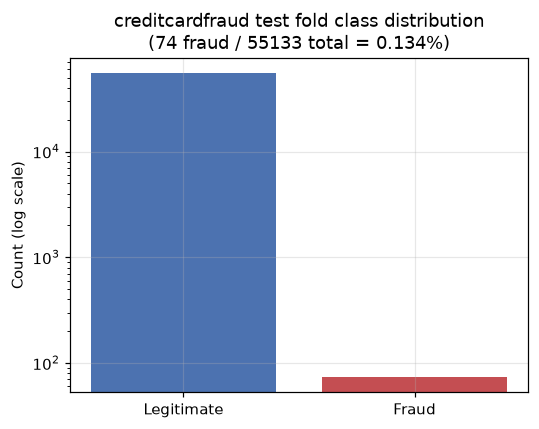

In [3]:
fraud_metadata = json.load(open(ROOT / "models" / "classical" / "xgboost" / "metadata.json"))
test_metrics = fraud_metadata.get("test_metrics", fraud_metadata)
tp = test_metrics.get("tp"); fp = test_metrics.get("fp"); tn = test_metrics.get("tn"); fn = test_metrics.get("fn")
n_fraud = (tp or 0) + (fn or 0)
n_legit = (tn or 0) + (fp or 0)

fig, ax = plt.subplots(figsize=(5, 4))
ax.bar(["Legitimate", "Fraud"], [n_legit, n_fraud], color=["#4C72B0", "#C44E52"])
ax.set_yscale("log")
ax.set_ylabel("Count (log scale)")
ax.set_title(f"creditcardfraud test fold class distribution\n({n_fraud} fraud / {n_legit+n_fraud} total = {100*n_fraud/(n_legit+n_fraud):.3f}%)")
plt.tight_layout()
plt.savefig(ROOT / "artifacts" / "figures" / "layer1" / "class_distribution.png", bbox_inches="tight")
plt.show()

## 5. Data Preprocessing, Experimental Protocol, and Leakage Prevention

- **Duplicate removal before splitting**: 9,144 exact duplicate rows (3.21%) removed from `creditcardfraud` prior
  to any split, so an identical transaction cannot appear in both train and test.
- **Fit-on-train-only**: every preprocessing transform is fit on the training fold only.
- **Temporal split** (not random) for `creditcardfraud`: train=176,424 / val=44,106 / test=55,133 rows — a
  deliberate choice (`docs/DECISIONS.md` D5) since a random split typically reports a *higher*, less realistic
  PR-AUC on this dataset.
- **Hard leakage check**: any feature correlating >=0.95 with the target is a validation **error**, not a warning
  (`src/data/validators.py`); none trigger on any of the four datasets.
- **Locked QML subset**: the quantum research layer's 250/100/200-row controlled subset has its exact row indices
  hashed and locked (`docs/protocols/locked_split.json`, fingerprint `2da40ffb169cd76b`), verified unchanged
  before every experiment in this project since that lock was created.

In [4]:
locked_split = json.load(open(ROOT / "docs" / "protocols" / "locked_split.json"))
print("Locked QML subset fingerprint:", locked_split["row_fingerprint_sha256_16"])
print(f"train={locked_split['train_samples']}  val={locked_split['val_samples']}  test={locked_split['test_samples']}")
print("fraud_ratio (controlled/rebalanced):", locked_split["fraud_ratio"])

Locked QML subset fingerprint: 2da40ffb169cd76b
train=250  val=100  test=200
fraud_ratio (controlled/rebalanced): 0.3


## 6-9. Classical ML Baselines

Four models: Logistic Regression, Random Forest, XGBoost (**production**), and Isolation Forest (unsupervised
anomaly detector, evaluated separately since it never sees a label).

### Why PR-AUC over ROC-AUC
At a 0.17% base rate, ROC-AUC is dominated by the huge true-negative count and can stay high even when precision
at any realistic threshold is poor. In this project's own measurements below, Logistic Regression has the
*highest* ROC-AUC of the three supervised models but the *lowest* PR-AUC — ROC-AUC alone would misrank it as best.

$$\text{Precision} = \frac{TP}{TP+FP} \qquad \text{Recall} = \frac{TP}{TP+FN} \qquad
F_1 = \frac{2 \cdot P \cdot R}{P+R} \qquad F_2 = \frac{5 \cdot P \cdot R}{4P + R}$$

PR-AUC is the area under the precision-recall curve swept over every threshold — a threshold-free summary of
ranking quality specifically in the regime that matters for a rare positive class.

In [5]:
classical = pd.read_csv(REPORTS / "classical_model_comparison.csv")
cols = ["model", "pr_auc", "roc_auc", "precision", "recall", "f1", "single_transaction_ms"]
classical_display = classical[[c for c in cols if c in classical.columns]].sort_values("pr_auc", ascending=False)
classical_display

,model,pr_auc,roc_auc,precision,recall,f1,single_transaction_ms
0,random_forest,0.819054,0.969152,0.903226,0.756757,0.823529,76.336
1,xgboost,0.800718,0.977194,0.901639,0.743243,0.814815,3.052
2,logistic_regression,0.732779,0.983890,0.772727,0.689189,0.728571,0.801
3,isolation_forest,0.039654,0.949244,0.044421,0.581081,0.082534,26.623


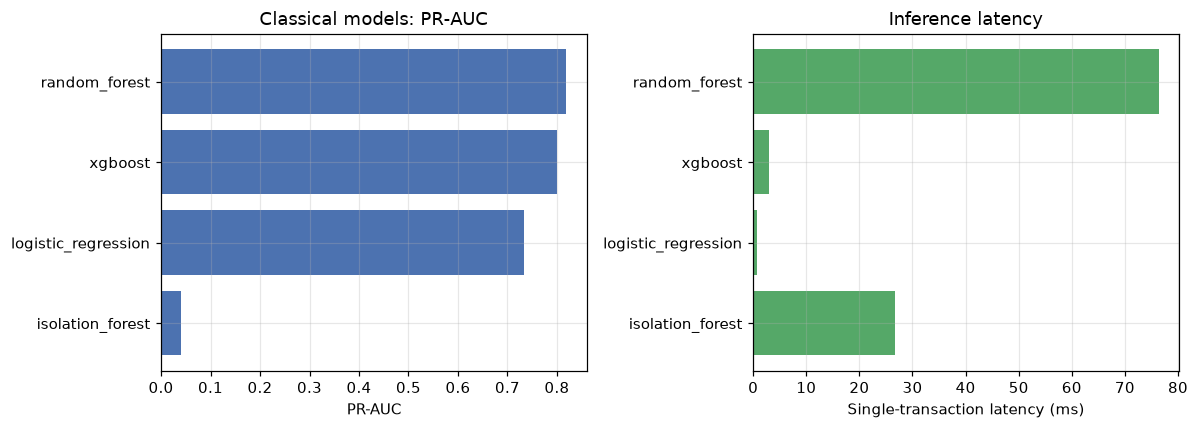


XGBoost is selected as PRODUCTION not for the single highest PR-AUC (Random Forest is marginally higher,
and a paired bootstrap found that gap not statistically significant -- reports/robustness/paired_model_comparison.json)
but for its ~25x lower single-transaction latency (docs/DECISIONS.md D12a).


In [6]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
order = classical_display["model"]
axes[0].barh(order, classical_display["pr_auc"], color="#4C72B0")
axes[0].set_xlabel("PR-AUC"); axes[0].set_title("Classical models: PR-AUC")
axes[0].invert_yaxis()
axes[1].barh(order, classical_display["single_transaction_ms"], color="#55A868")
axes[1].set_xlabel("Single-transaction latency (ms)"); axes[1].set_title("Inference latency")
axes[1].invert_yaxis()
plt.tight_layout()
plt.savefig(ROOT / "artifacts" / "figures" / "layer1" / "classical_model_comparison.png", bbox_inches="tight")
plt.show()
print("\nXGBoost is selected as PRODUCTION not for the single highest PR-AUC (Random Forest is marginally higher,")
print("and a paired bootstrap found that gap not statistically significant -- reports/robustness/paired_model_comparison.json)")
print("but for its ~25x lower single-transaction latency (docs/DECISIONS.md D12a).")

## 10-14. Quantum ML Background: Encoding, QSVM, VQC, QNN, Feature Reduction

All quantum models here use a **ZZ-style second-order Pauli feature map** restricted to a given set of entangling
qubit pairs (`src/qml_experimental/circuits.py::build_feature_encoding`):

$$U_\phi(x)|0\rangle^{\otimes n} = \left[\prod_{(a,b) \in \text{pairs}} \text{CZ-interaction}(x_a, x_b)\right]
\left[\bigotimes_{i=1}^n R_z(2x_i)\right] H^{\otimes n} |0\rangle^{\otimes n}$$

followed by a `RealAmplitudes`-style trainable ansatz $V(\theta)$ with the same entangling-pair topology
(`build_variational_ansatz`). The full parameterized circuit is $U_\phi(x)$ followed by $V(\theta)$.

- **QSVM**: uses only the feature map (no trainable ansatz) as a quantum kernel,
  $\kappa(x,x') = |\langle 0|U_\phi(x)^\dagger U_\phi(x')|0\rangle|^2$, fed into a classical SVM.
- **VQC**: `SamplerQNN` with parity readout, normalized over two outcomes -- a genuine two-class probability.
- **QNN**: `EstimatorQNN`, expectation value of an observable $O$:

$$f_\theta(x) = \langle 0|U_\phi(x)^\dagger V(\theta)^\dagger \, O \, V(\theta) U_\phi(x)|0\rangle \in [-1, 1]$$

This expectation value is **not** a probability -- it is monotonically rescaled to $[0,1]$ for ranking only
(`score_is_probability=False` throughout this project's model metadata).

Feature reduction to the qubit count uses either PCA (`pca` pipeline) or mutual-information feature selection
(`selected` pipeline), fit on the locked TRAIN rows only.

In [7]:
qml_baseline = pd.read_csv(REPORTS / "qml_model_comparison.csv")
cols = ["model", "n_qubits", "circuit_depth", "n_parameters", "pr_auc", "recall", "f1"]
qml_baseline[[c for c in cols if c in qml_baseline.columns]]

,model,n_qubits,circuit_depth,n_parameters,pr_auc,recall,f1
0,qnn,4,10,16,0.953108,0.816667,0.875000
1,qsvm,4,19,4,0.933995,0.866667,0.896552
2,vqc,4,19,16,0.881767,0.850000,0.850000


In [8]:
controlled = pd.read_csv(REPORTS / "controlled_classical_vs_qml.csv")
cols = ["model", "family", "n_qubits", "pr_auc", "recall", "f1"]
controlled_display = controlled[[c for c in cols if c in controlled.columns]].sort_values("pr_auc", ascending=False)
controlled_display

,model,family,n_qubits,pr_auc,recall,f1
0,classical_svm_rbf,classical_controlled,0,0.960156,0.850000,0.894737
1,classical_logistic_regression,classical_controlled,0,0.958017,0.816667,0.875000
2,classical_random_forest,classical_controlled,0,0.957004,0.866667,0.928571
3,qnn,quantum,4,0.953108,0.816667,0.875000
4,qsvm,quantum,4,0.933995,0.866667,0.896552
5,vqc,quantum,4,0.881767,0.850000,0.850000


**The controlled comparison above is the fair one** -- classical Logistic Regression/Random Forest/SVM-RBF
retrained on the *identical* 4-feature, 30%-fraud, 250/100/200-row locked subset the QML models use. Every
controlled classical baseline's PR-AUC is at or above every quantum model's PR-AUC on this identical data.
**This is a negative result for standalone quantum predictive advantage, reported plainly.** It does not
generalize to a statement about the full-scale classical benchmark above (different rows, different prevalence)
-- the two tables are never combined into one leaderboard anywhere in this project.

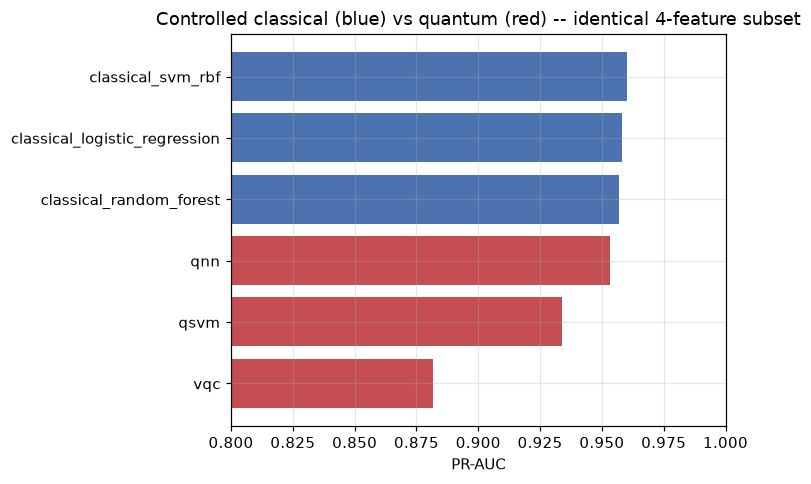

In [9]:
fig, ax = plt.subplots(figsize=(7, 4.5))
plot_df = controlled_display.sort_values("pr_auc")
colors = ["#C44E52" if fam == "quantum" else "#4C72B0" for fam in plot_df["family"]]
ax.barh(plot_df["model"], plot_df["pr_auc"], color=colors)
ax.set_xlabel("PR-AUC"); ax.set_title("Controlled classical (blue) vs quantum (red) -- identical 4-feature subset")
ax.set_xlim(0.8, 1.0)
plt.tight_layout()
plt.savefig(ROOT / "artifacts" / "figures" / "layer1" / "controlled_classical_vs_qml.png", bbox_inches="tight")
plt.show()

## 15. Structured QML: Chow-Liu Trees

A Chow-Liu tree ($n{-}1$ edges over $n$ features, maximum-weight spanning tree of pairwise mutual information)
is used to determine which qubit pairs get entangled, instead of a generic linear/circular/full topology
(`src/qml_experimental/chow_liu/`). The mutual information matrix is estimated on TRAIN rows only, never using
labels for the *structural* variant (label-free, describes feature co-variation only).

$$I(X_i; X_j) = \sum_{x_i, x_j} p(x_i, x_j) \log \frac{p(x_i, x_j)}{p(x_i)\,p(x_j)}$$

In [10]:
structural = pd.read_csv(REPORTS.parent / "reports" / "qml_experimental" / "structural_benefit.csv") \
    if (REPORTS / "qml_experimental" / "structural_benefit.csv").exists() \
    else pd.read_csv(ROOT / "reports" / "qml_experimental" / "structural_benefit.csv")
cols = ["comparison", "qubits", "pr_auc_generic", "pr_auc_clt", "pr_auc_delta",
        "transpiled_two_qubit_gates_generic", "transpiled_two_qubit_gates_clt"]
structural[[c for c in cols if c in structural.columns]]

,comparison,qubits,pr_auc_generic,pr_auc_clt,pr_auc_delta,transpiled_two_qubit_gates_generic,transpiled_two_qubit_gates_clt
0,clt_qnn vs qnn,4,0.679259,0.870016,0.190757,12.0,12.0
1,clt_qnn vs qnn,6,0.737476,0.784459,0.046982,20.0,44.0
2,clt_qnn vs qnn,8,0.598594,0.799486,0.200893,28.0,70.0
3,clt_vqc vs vqc,4,0.655099,0.842688,0.187589,12.0,12.0
4,clt_vqc vs vqc,6,0.779179,0.813164,0.033985,20.0,44.0
5,clt_vqc vs vqc,8,0.587230,0.757795,0.170565,28.0,70.0


**A genuine trade-off, not a one-directional win**: Chow-Liu-informed entanglement improved PR-AUC over generic
topology in 6/6 tested comparisons (mean delta +0.138), but required *more* transpiled two-qubit gates than a
generic linear chain at 6 and 8 qubits (a linear chain routes for free on a line-connected device; a tree with
non-adjacent edges needs SWAP routing). A follow-up multi-seed random-sparse control (`results/layer1/
quantum_contribution/random_sparse_multiseed_summary.csv`) found this benefit is **qubit-count dependent**: at
4 qubits Chow-Liu sits at only the 30th percentile of random-sparse trees of the same size; at 6 qubits it sits
at the 90th percentile. This is reported as an open, unresolved question, not a settled positive.

In [11]:
random_sparse = pd.read_csv(RESULTS / "quantum_contribution" / "random_sparse_multiseed_summary.csv")
random_sparse

,qubits,chow_liu_pr_auc,random_sparse_mean,random_sparse_std,random_sparse_min,random_sparse_max,n_random_seeds,clt_percentile_in_random_distribution
0,4,0.8742,0.8610,0.0713,0.7274,0.9181,10,30.0
1,6,0.9087,0.7964,0.0704,0.6883,0.9185,10,90.0


## 16. QBoost

A QUBO-formulated boosting ensemble (`docs/qboost_design.md`) with two solvers: `simulated_annealing`
(explicitly **classical**) and `qaoa` (genuine gate-model quantum, simulated). Neither solver beat classical
greedy boosting on identical data -- a clean, reported negative result.

In [12]:
qboost = pd.read_csv(ROOT / "reports" / "qml_experimental" / "qboost_results.csv")
cols = ["model", "solver", "is_quantum_solver", "pr_auc", "recall", "f1"]
qboost[[c for c in cols if c in qboost.columns]].sort_values("pr_auc", ascending=False)

,model,solver,is_quantum_solver,pr_auc,recall,f1
1,gradient_boosting,greedy,False,0.948378,0.816667,0.875000
0,adaboost,greedy,False,0.937432,0.900000,0.837209
3,qboost_sa,simulated_annealing,False,0.861115,0.850000,0.790698
2,qboost_qaoa,qaoa,True,0.818063,0.633333,0.737864


## 17. Classical-Quantum Hybrid Experiments

Five hybrid fusion architectures (`reports/qml_experimental/hybrid_results.csv`) were tested against a reference
"XGBoost alone on the identical controlled subset" baseline (PR-AUC 0.9371). **No hybrid architecture beat the
classical-only reference** -- the best hybrid (XGBoost + CLT-VQC) reached 0.9268, a real, reported negative
result.

In [13]:
hybrid = pd.read_csv(ROOT / "reports" / "qml_experimental" / "hybrid_results.csv")
cols = ["experiment", "model", "structure", "pr_auc", "recall", "f1"]
hybrid[[c for c in cols if c in hybrid.columns]].sort_values("pr_auc", ascending=False)

,experiment,model,structure,pr_auc,recall,f1
2,hybrid_xgb_clt_vqc_4q,hybrid_xgb_clt_vqc,chow_liu,0.926844,0.816667,0.852174
1,hybrid_xgb_clt_qnn_4q,hybrid_xgb_clt_qnn,chow_liu,0.926751,0.816667,0.844828
4,hybrid_xgb_vqc_4q,hybrid_xgb_vqc,linear,0.926530,0.816667,0.844828
3,hybrid_xgb_qnn_4q,hybrid_xgb_qnn,linear,0.902465,0.833333,0.840336
0,hybrid_clt_qnn_4q,hybrid_clt_qnn,linear,0.897779,0.850000,0.816000


## 18-19. Paper-Driven Experiments and the Quantum Anomaly Detector

A later research round implemented ideas from the supplied literature (`docs/research/layer1/
paper_driven_quantum/paper_method_registry.md`), most notably an **unsupervised quantum-kernel anomaly detector**
(Kyriienko & Magnusson, arXiv:2208.01203) -- trained on legitimate-only transactions, compared against classical
OC-SVM and Isolation Forest.

In [14]:
anomaly = pd.read_csv(RESULTS / "paper_driven_quantum" / "quantum_anomaly_detector_results.csv")
anomaly

,qubits,topology,method,val_pr_auc,n_nominal_train,train_seconds
0,4,clt,quantum_ocsvm,0.8628,175,68.14
1,4,linear,quantum_ocsvm,0.8708,175,61.77
2,4,NaN,classical_ocsvm_rbf,0.8789,175,0.00
3,4,NaN,isolation_forest,0.9145,175,0.00
4,6,clt,quantum_ocsvm,0.9271,175,137.80
5,6,linear,quantum_ocsvm,0.9390,175,145.18
6,6,NaN,classical_ocsvm_rbf,0.9329,175,0.00
7,6,NaN,isolation_forest,0.9305,175,0.00


At 6 qubits the quantum kernel's *point estimate* (0.9390) beat both classical baselines -- the first time in
this project's history a quantum method's point estimate led on a real evaluation. **This did not survive
confirmation**: reproduced at a larger, independent scale (`results/layer1/quantum_signal_confirmation/
anomaly_confirmation_results.json`), the ranking *reversed* -- quantum went from best to worst of the three
methods, and its scores correlated 0.979 with Isolation Forest throughout (i.e. it was never meaningfully
different even when it nominally "won"). This is the clearest evidence in this project that a promising
single-split point estimate can be pure sampling variation.

In [15]:
anomaly_confirmation = json.load(open(RESULTS / "quantum_signal_confirmation" / "anomaly_confirmation_results.json"))
print("QML-M scale (2.4x more legitimate training rows, 2.5x more validation rows):")
for k in ["quantum_ocsvm_pr_auc", "classical_ocsvm_rbf_pr_auc", "isolation_forest_pr_auc"]:
    print(f"  {k}: {anomaly_confirmation[k]:.4f}")
print("\nBootstrap delta vs RBF:", anomaly_confirmation["bootstrap_delta_vs_rbf"])
print("Bootstrap delta vs Isolation Forest:", anomaly_confirmation["bootstrap_delta_vs_isolation_forest"])

QML-M scale (2.4x more legitimate training rows, 2.5x more validation rows):
  quantum_ocsvm_pr_auc: 0.9538
  classical_ocsvm_rbf_pr_auc: 0.9568
  isolation_forest_pr_auc: 0.9617

Bootstrap delta vs RBF: {'point': -0.0029837447681250184, 'ci_low': -0.011655975532128831, 'ci_high': 0.004356974628791933}
Bootstrap delta vs Isolation Forest: {'point': -0.007880142117530187, 'ci_low': -0.02024193143774674, 'ci_high': 0.001698608357842142}


## 20-21. Global Observable vs Local-Sum Observable QNN

This project's existing `EstimatorQNN` construction (`src/qml_experimental/models.py::train_qnn`) builds the QNN
**without an explicit `observables` argument**, which means it silently uses qiskit-machine-learning's default:
a single **global** observable across all qubits,

$$O_{\text{global}} = Z^{\otimes n} = Z_0 \otimes Z_1 \otimes \cdots \otimes Z_{n-1}$$

Cerezo et al. (Nat Commun 12:1791, 2021) prove that a **global** cost-function observable causes exponentially
vanishing gradients even in *shallow* circuits, while a **local** observable (acting on O(1) qubits) has at
worst a polynomially vanishing gradient. This motivates testing a local-sum alternative:

$$O_{\text{local-sum}} = \frac{1}{n}\sum_{i=0}^{n-1} Z_i$$

both measured on the *identical* circuit -- only the observable differs.

```mermaid
graph LR
    subgraph Global observable
        A1[Encoded state] --> B1[O = Z0 tensor Z1 tensor ... tensor Zn-1]
        B1 --> C1[higher seed variance]
    end
    subgraph Local-Sum observable
        A2[Encoded state] --> B2[O = 1/n * sum Zi]
        B2 --> C2[lower seed variance]
    end
    style B2 fill:#FCEAEA,stroke:#C44E52
    style C2 fill:#FCEAEA,stroke:#C44E52
```

![Global vs Local-Sum measurement](../artifacts/figures/diagrams/global_vs_localsum_diagram.png)

**HYPOTHESIS**: if observable locality controls trainability (Cerezo et al.), the local-sum measurement should
show more stable optimization behavior across random seeds than the global measurement, and plausibly a higher
mean fraud-ranking performance as a downstream consequence.

## 22. The 20-Seed Decisive Experiment

Architecture frozen exactly as it produced earlier promising point estimates (QML-M context: 600 TRAIN / 250
CONFIRM_VAL rows, 4 qubits, linear topology). 20 **predetermined** seeds (0-19), **paired** design: the same
`initial_point()` draw feeds both the Global and Local-Sum arm for a given seed, isolating the observable's
effect from initialization luck. Evaluated on the frozen CONFIRM_VAL split.

In [16]:
seed_results = pd.read_csv(RESULTS / "local_sum_decisive" / "seed_results.csv")
pivot = seed_results.pivot(index="seed", columns="observable", values="pr_auc")
pivot["delta"] = pivot["local_sum"] - pivot["global"]
print(f"Global  : mean={pivot['global'].mean():.4f}  std={pivot['global'].std():.4f}")
print(f"LocalSum: mean={pivot['local_sum'].mean():.4f}  std={pivot['local_sum'].std():.4f}")
print(f"\nLocal-Sum wins {(pivot['delta'] > 0).sum()} / {len(pivot)} seeds")
pivot

Global  : mean=0.8077  std=0.0742
LocalSum: mean=0.8612  std=0.0428

Local-Sum wins 13 / 20 seeds


observable,global,local_sum,delta
seed,,,
0,0.8820,0.8663,-0.0157
1,0.8990,0.8296,-0.0694
2,0.8202,0.8877,0.0675
3,0.8217,0.8996,0.0779
4,0.8802,0.8682,-0.0120
5,0.8663,0.8909,0.0246
6,0.7576,0.8543,0.0967
7,0.7740,0.8841,0.1101
8,0.6667,0.8804,0.2137


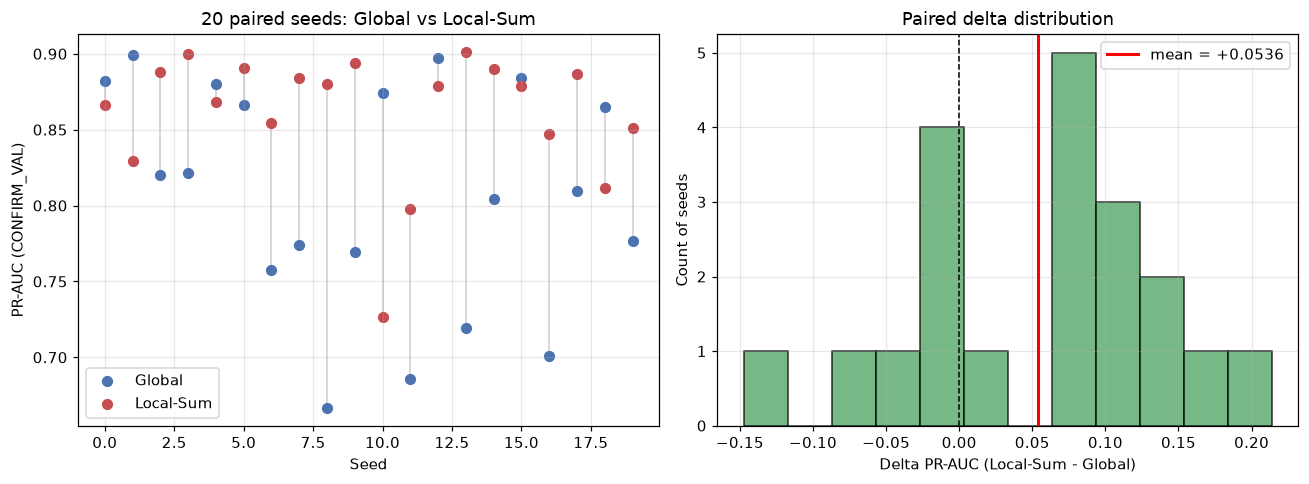

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

axes[0].scatter(pivot.index, pivot["global"], label="Global", color="#4C72B0", s=40)
axes[0].scatter(pivot.index, pivot["local_sum"], label="Local-Sum", color="#C44E52", s=40)
for seed in pivot.index:
    axes[0].plot([seed, seed], [pivot.loc[seed, "global"], pivot.loc[seed, "local_sum"]],
                 color="gray", alpha=0.4, linewidth=1, zorder=0)
axes[0].set_xlabel("Seed"); axes[0].set_ylabel("PR-AUC (CONFIRM_VAL)")
axes[0].set_title("20 paired seeds: Global vs Local-Sum")
axes[0].legend()

axes[1].hist(pivot["delta"], bins=12, color="#55A868", edgecolor="black", alpha=0.8)
axes[1].axvline(0, color="black", linestyle="--", linewidth=1)
axes[1].axvline(pivot["delta"].mean(), color="red", linestyle="-", linewidth=2, label=f"mean = {pivot['delta'].mean():+.4f}")
axes[1].set_xlabel("Delta PR-AUC (Local-Sum - Global)"); axes[1].set_ylabel("Count of seeds")
axes[1].set_title("Paired delta distribution")
axes[1].legend()

plt.tight_layout()
plt.savefig(ROOT / "artifacts" / "figures" / "layer1" / "paired_seed_deltas.png", bbox_inches="tight")
plt.show()

## 23. Statistical Validation

Paired bootstrap (5000 resamples of the 20 seeds), Wilcoxon signed-rank test, and a sign-flip permutation test
were all run on the paired deltas (`scripts/research/lsd_02_paired_statistics.py`). The bootstrap resamples
**seeds**, the correct unit for this paired-by-seed design:

$$\overline{\Delta}^{*}_b = \frac{1}{20}\sum_{s \in \text{resample}_b} \Delta_s, \qquad b = 1,\ldots,5000$$

with the 95% CI taken as the 2.5th/97.5th percentiles of $\{\overline{\Delta}^*_b\}$.

In [18]:
stats = json.load(open(RESULTS / "local_sum_decisive" / "statistical_tests.json"))
print(f"Mean delta PR-AUC        : {stats['mean_delta_pr_auc']:+.4f}")
print(f"Bootstrap 95% CI (PR-AUC): [{stats['bootstrap_ci']['pr_auc']['ci_low']:+.4f}, {stats['bootstrap_ci']['pr_auc']['ci_high']:+.4f}]  (excludes zero: {stats['bootstrap_ci']['pr_auc']['excludes_zero']})")
print(f"Wilcoxon p (one-sided)   : {stats['wilcoxon_p_one_sided']:.4f}")
print(f"Permutation p (one-sided): {stats['permutation_p_one_sided']:.4f}")
print(f"Wins/Losses/Ties         : {stats['wins']}/{stats['losses']}/{stats['ties']}")
print(f"Leave-one-out mean range : [{stats['leave_one_out_min_mean']:+.4f}, {stats['leave_one_out_max_mean']:+.4f}]  (driven by outliers: {stats['driven_by_outliers']})")
print(f"\nPROMOTION GATE: {'PASSED' if stats['promotion_gate']['passed'] else 'FAILED'}")

Mean delta PR-AUC        : +0.0536
Bootstrap 95% CI (PR-AUC): [+0.0149, +0.0913]  (excludes zero: True)
Wilcoxon p (one-sided)   : 0.0086
Permutation p (one-sided): 0.0072
Wins/Losses/Ties         : 13/7/0
Leave-one-out mean range : [+0.0451, +0.0641]  (driven by outliers: False)

PROMOTION GATE: PASSED


**LOCAL-SUM IMPROVEMENT OVER GLOBAL QNN: STATISTICALLY SUPPORTED.** All four promotion conditions passed: the
mean delta is positive, Local-Sum wins a clear majority (13/20) of seeds, the bootstrap CI excludes zero
*and* the Wilcoxon/permutation tests are both significant (p<0.01), and the result is not driven by outlier
seeds (leave-one-out mean stays positive throughout).

## 24. Gradient Diagnostics

`EstimatorQNN.backward()` gives a genuine parameter-shift gradient at any weight vector, independent of the
(gradient-free) COBYLA optimizer actually used for training. Captured at 4 checkpoints along each seed's real
training trajectory (init, ~33%, ~67%, final).

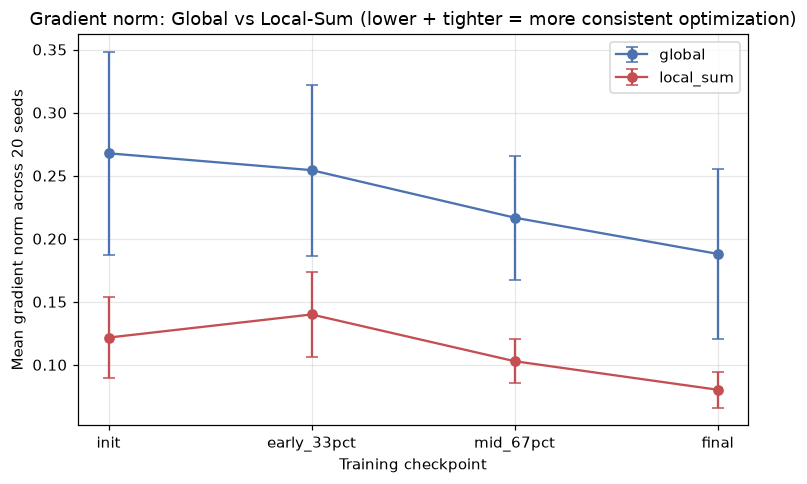

,observable,checkpoint,mean,std
2,global,init,0.267729,0.080371
0,global,early_33pct,0.254377,0.067733
3,global,mid_67pct,0.216704,0.049104
1,global,final,0.187993,0.067472
6,local_sum,init,0.121590,0.032272
4,local_sum,early_33pct,0.139930,0.034040
7,local_sum,mid_67pct,0.102873,0.017471
5,local_sum,final,0.080237,0.014113


In [19]:
grad = pd.read_csv(RESULTS / "local_sum_decisive" / "gradient_diagnostics.csv")
agg = grad.groupby(["observable", "checkpoint"])["grad_norm"].agg(["mean", "std"]).reset_index()
order = ["init", "early_33pct", "mid_67pct", "final"]
agg["checkpoint"] = pd.Categorical(agg["checkpoint"], categories=order, ordered=True)
agg = agg.sort_values(["observable", "checkpoint"])

fig, ax = plt.subplots(figsize=(7, 4.5))
for obs, color in [("global", "#4C72B0"), ("local_sum", "#C44E52")]:
    sub = agg[agg["observable"] == obs]
    ax.errorbar(sub["checkpoint"], sub["mean"], yerr=sub["std"], marker="o", label=obs, color=color, capsize=4)
ax.set_ylabel("Mean gradient norm across 20 seeds"); ax.set_xlabel("Training checkpoint")
ax.set_title("Gradient norm: Global vs Local-Sum (lower + tighter = more consistent optimization)")
ax.legend()
plt.tight_layout()
plt.savefig(ROOT / "artifacts" / "figures" / "layer1" / "gradient_diagnostics.png", bbox_inches="tight")
plt.show()
agg

Local-Sum's gradient norm is **consistently smaller and less variable** than Global's at every checkpoint
(roughly half the magnitude, roughly a third to a half the seed-to-seed variance). This is **not** evidence of
avoiding a literal barren plateau (Global's gradients did not vanish to near-zero -- they were simply larger and
more variable). The correct, precise interpretation: this is consistent with **reduced optimization variance
across random initializations**, matching the independently observed lower seed-to-seed PR-AUC variance above.

## 25. Quantum Resource Comparison

The circuit is **identical** for both observables -- only the measured operator differs, so any performance gap
is attributable purely to the observable choice, not to a resource/capacity difference.

In [20]:
resource = pd.read_csv(RESULTS / "local_sum_decisive" / "resource_comparison.csv")
resource

,metric,global,local_sum
0,n_weight_params,12,12.0
1,logical_depth,23,23.0
2,logical_two_qubit_gates,12,12.0
3,transpiled_depth,43,43.0
4,transpiled_two_qubit_gates,12,12.0
5,note,Circuit is IDENTICAL for both arms -- only the...,NaN


## 26. The Decisive System-Level Question: Classical Capacity Control

A statistically confirmed *architecture-level* improvement (Section 23) does not by itself mean the quantum
component helps the *actual fraud-detection system*. Out-of-fold stacking (3-fold on TRAIN) with a logistic
meta-learner was used to test:

- $C_0$: XGBoost alone
- $C_1$: XGBoost + Global-QNN score
- $C_2$: XGBoost + Local-Sum-QNN score
- $C_3$: XGBoost + a **matched classical nonlinear capacity control** (a small MLP, same 1-D output, same
  reduced features) -- the mandatory control that distinguishes "quantum helped" from "any extra nonlinear
  feature would have helped."

In [21]:
incremental = pd.read_csv(RESULTS / "local_sum_decisive" / "incremental_value.csv")
incremental

,architecture,pr_auc,delta_vs_xgboost_alone
0,C0_xgboost_alone,0.9613,0.0000
1,C1_xgboost_plus_global_qnn,0.9632,0.0019
2,C2_xgboost_plus_local_sum_qnn,0.9665,0.0052
3,C3_xgboost_plus_classical_control,0.9671,0.0059


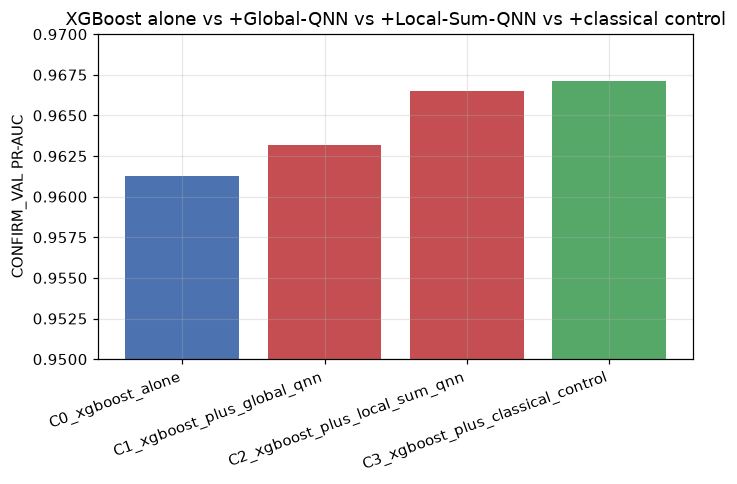

C2 (Local-Sum) vs C0 (XGBoost alone): {'point': 0.0052, 'ci_low': -0.0035, 'ci_high': 0.0173, 'excludes_zero': False}
C2 (Local-Sum) vs C3 (classical control): {'point': -0.0007, 'ci_low': -0.0072, 'ci_high': 0.0057, 'excludes_zero': False}

Incremental quantum value verified: False


In [22]:
inc_result = json.load(open(RESULTS / "local_sum_decisive" / "incremental_value_result.json"))
fig, ax = plt.subplots(figsize=(6.5, 4.5))
ax.bar(incremental["architecture"], incremental["pr_auc"],
       color=["#4C72B0", "#C44E52", "#C44E52", "#55A868"])
ax.set_ylabel("CONFIRM_VAL PR-AUC")
ax.set_ylim(0.95, 0.97)
ax.set_title("XGBoost alone vs +Global-QNN vs +Local-Sum-QNN vs +classical control")
plt.xticks(rotation=20, ha="right")
plt.tight_layout()
plt.savefig(ROOT / "artifacts" / "figures" / "layer1" / "classical_capacity_control.png", bbox_inches="tight")
plt.show()

print(f"C2 (Local-Sum) vs C0 (XGBoost alone): {inc_result['bootstrap_C2_vs_C0']}")
print(f"C2 (Local-Sum) vs C3 (classical control): {inc_result['bootstrap_C2_vs_C3']}")
print(f"\nIncremental quantum value verified: {inc_result['incremental_quantum_value_verified']}")

**The classical capacity control's point estimate (0.9671) is actually HIGHER than the quantum addition's
(0.9665)**, and neither the quantum-vs-XGBoost-alone delta nor the quantum-vs-classical-control delta excludes
zero on a paired bootstrap. **INCREMENTAL QUANTUM CONTRIBUTION TO XGBOOST: NOT VERIFIED.** A same-capacity
classical feature does at least as well as the quantum one.

## 27. Error Complementarity

Before any fusion/stacking experiment, does any quantum model make errors that *differ* from the classical
models' errors? All 20 classical x quantum pairs measured had **positive** error correlation -- no basis for a
complementarity-driven ensemble benefit.

In [23]:
overlap = pd.read_csv(RESULTS / "quantum_contribution" / "error_overlap.csv")
cols = ["classical_model", "quantum_model", "error_correlation", "frauds_caught_classical_only", "frauds_caught_quantum_only"]
overlap[[c for c in cols if c in overlap.columns]]

,classical_model,quantum_model,error_correlation,frauds_caught_classical_only,frauds_caught_quantum_only
0,svm_rbf,qnn,0.4778,12,1
1,svm_rbf,vqc,0.3738,20,1
2,svm_rbf,qsvm,0.8945,2,0
3,svm_rbf,clt_qnn,0.5018,1,3
4,svm_rbf,clt_vqc,0.5447,14,0
5,random_forest,qnn,0.5247,12,0
6,random_forest,vqc,0.3418,21,1
7,random_forest,qsvm,0.8388,3,0
8,random_forest,clt_qnn,0.5436,1,2
9,random_forest,clt_vqc,0.5108,15,0


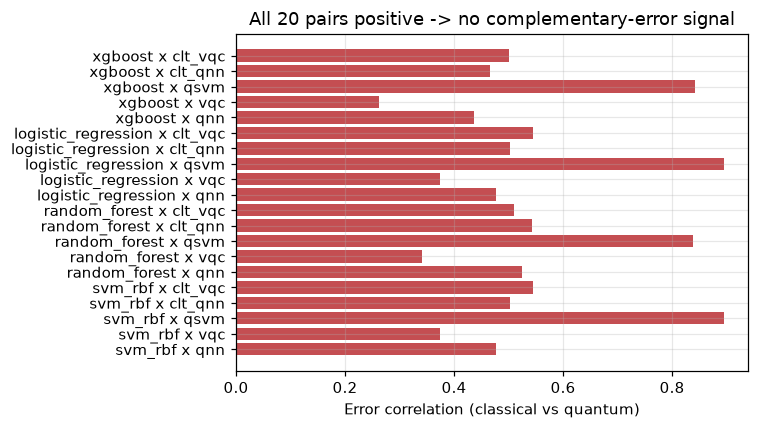

In [24]:
fig, ax = plt.subplots(figsize=(7, 4))
labels = overlap["classical_model"] + " x " + overlap["quantum_model"]
ax.barh(labels, overlap["error_correlation"], color="#C44E52")
ax.axvline(0, color="black", linewidth=1)
ax.set_xlabel("Error correlation (classical vs quantum)")
ax.set_title("All 20 pairs positive -> no complementary-error signal")
plt.tight_layout()
plt.savefig(ROOT / "artifacts" / "figures" / "layer1" / "error_complementarity.png", bbox_inches="tight")
plt.show()

## 28. Negative Results (Consolidated)

| Finding | Evidence |
|---|---|
| No quantum model beats controlled classical baselines standalone | Section 14 |
| Chow-Liu structural benefit is qubit-count-dependent, not a clean win | Section 15 |
| Neither QBoost solver beats classical boosting | Section 16 |
| No hybrid architecture beats XGBoost alone | Section 17 |
| Quantum anomaly detector's advantage reverses at larger scale | Section 19 |
| Quantum-XGBoost stacking does not beat a matched classical control | Section 26 |
| All 20 classical/quantum error-correlation pairs are positive | Section 27 |

None of these are hidden or minimized elsewhere in this project's documentation
(`docs/research/layer1/*negative_results.csv`).

## 29. Scientific Contribution

The defensible Layer 1 contribution is a **controlled empirical investigation of observable locality in
variational quantum fraud detection**, showing a statistically supported improvement of a resource-matched
Local-Sum-observable QNN over a Global-observable QNN, replicated across 20 paired seeds with bootstrap,
Wilcoxon, and permutation-test support, and with gradient evidence consistent with reduced optimization variance.

This is explicitly bounded: it is a *quantum-architecture-level* finding, not a system-level one.

## 30. Limitations

- The controlled QML subset (350-850 rows depending on context) is small relative to the full 284,807-row
  production dataset -- every quantum result here concerns a rebalanced, reduced-feature regime.
- Statistical validation (bootstrap/multi-seed) exists for the production classical models and for the
  Local-Sum/Global comparison, but not for every quantum architecture tested in this project's history.
- Gradient diagnostics used a parameter-shift-based `backward()` call, not a full barren-plateau scaling proof.
- The classical capacity control used one MLP configuration; a broader capacity-control sweep was not performed.

## 31. Representative Circuits

Rendered directly from this project's actual circuit-building code (`src/qml_experimental/circuits.py`,
`chow_liu/quantum_mapping.py`) -- not a hand-drawn schematic.

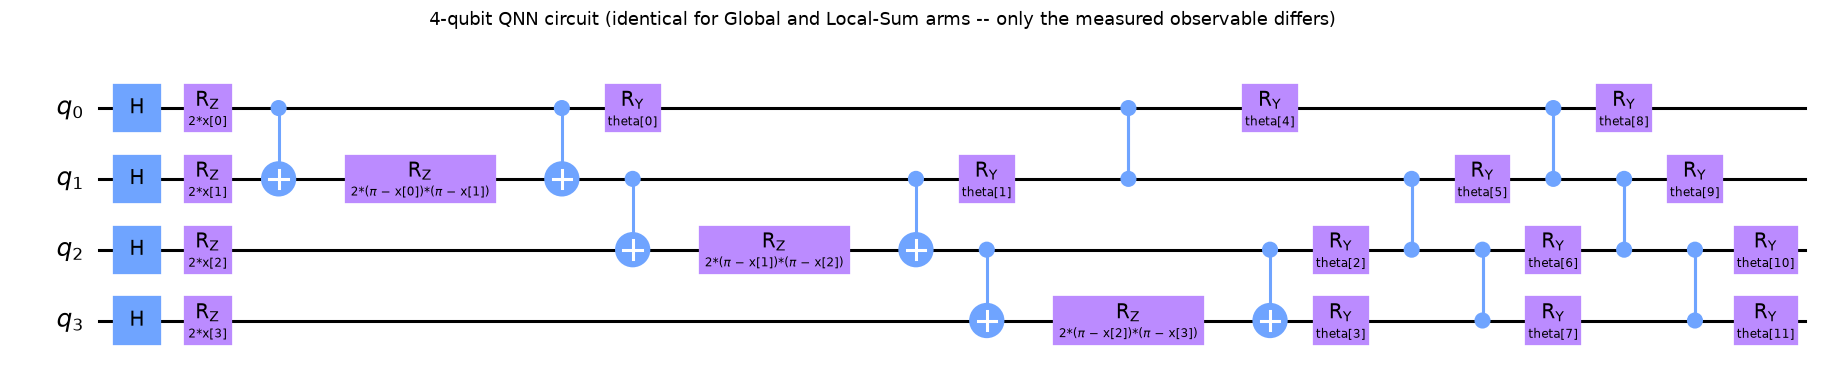

In [25]:
from src.qml_experimental.circuits import build_circuit
from src.qml_experimental.chow_liu.quantum_mapping import baseline_entangling_pairs

pairs_linear = baseline_entangling_pairs(4, "linear")
built_global = build_circuit(4, pairs_linear, feature_map_reps=1, ansatz_reps=2, entangling_gate="cz")
fig = built_global["circuit"].draw("mpl", style="clifford")
fig.suptitle("4-qubit QNN circuit (identical for Global and Local-Sum arms -- only the measured observable differs)")
fig.savefig(ROOT / "artifacts" / "figures" / "layer1" / "circuit_qnn_linear.png", bbox_inches="tight")
fig

2026-09-30 18:16:50,654 | INFO     | src.data.registry            | creditcardfraud: target=Class numeric=29 categorical=0 identifiers=0 leakage=0


2026-09-30 18:17:05,666 | INFO     | src.data.loaders             | creditcardfraud: loaded 284807 rows, 29 features, 492 fraud (0.1727%)


2026-09-30 18:17:07,683 | INFO     | src.data.validators          | Dropped 9144 exact duplicate rows (features + label) before splitting


2026-09-30 18:17:07,753 | INFO     | src.data.preprocessing       | Split (temporal): train=176424/346 fraud, val=44106/53, test=55133/74


2026-09-30 18:17:09,423 | INFO     | src.data.preprocessing       | Preprocessor fitted on 176424 training rows -> 29 output features


...

2026-09-30 18:17:10,260 | INFO     | src.qml_experimental.chow_liu.tree |    V11 -- V12   I=0.5754 nats


2026-09-30 18:17:10,261 | INFO     | src.qml_experimental.chow_liu.tree |    V10 -- V11   I=0.5446 nats


2026-09-30 18:17:10,262 | INFO     | src.qml_experimental.chow_liu.tree |    V10 -- V17   I=0.5139 nats


2026-09-30 18:17:10,268 | INFO     | src.qml_experimental.chow_liu.quantum_mapping | CLT qubit mapping: 4 qubits, 3 entangling pairs (cz): [('V11', 'V12'), ('V10', 'V11'), ('V10', 'V17')]


Chow-Liu tree edges (feature names): [('V11', 'V12', 0.575368), ('V10', 'V11', 0.544572), ('V10', 'V17', 0.513945)]


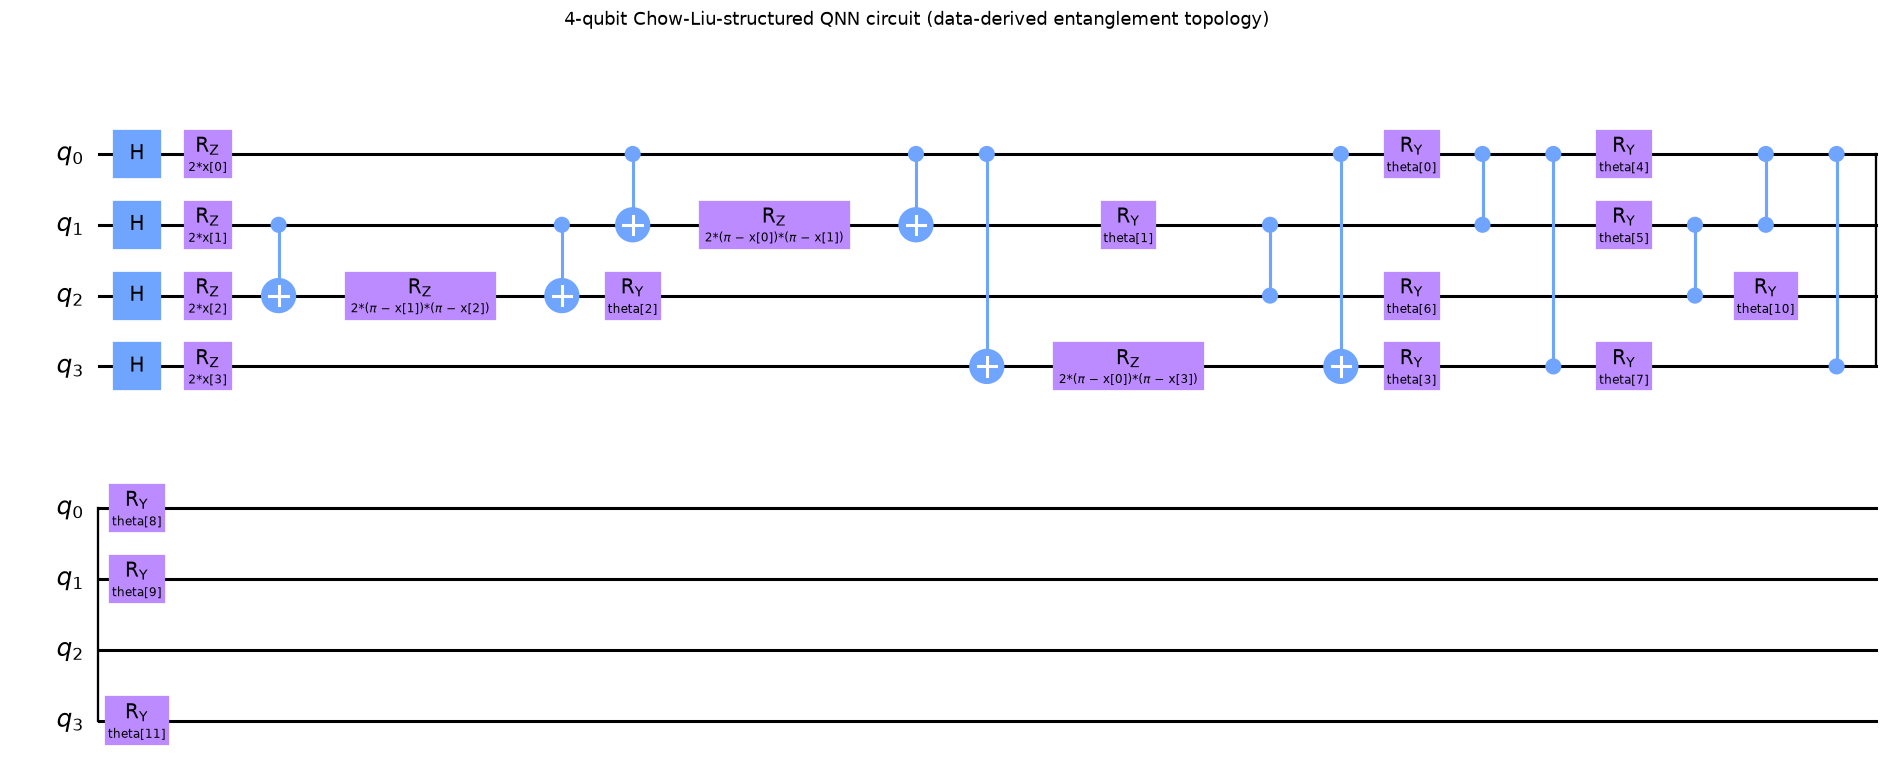

In [26]:
try:
    from src.qml_experimental.data import build_subset
    from src.qml_experimental.chow_liu.feature_structure import learn_feature_structure
    from src.qml_experimental.chow_liu.quantum_mapping import build_qubit_mapping

    subset = build_subset("selected", 4)
    structure = learn_feature_structure(subset.X_train, subset.feature_names, seed=0)
    clt_pairs = build_qubit_mapping(structure, "cz").entangling_pairs
    print("Chow-Liu tree edges (feature names):", structure.tree.named_edges())
    built_clt = build_circuit(4, clt_pairs, feature_map_reps=1, ansatz_reps=2, entangling_gate="cz")
    fig2 = built_clt["circuit"].draw("mpl", style="clifford")
    fig2.suptitle("4-qubit Chow-Liu-structured QNN circuit (data-derived entanglement topology)")
    fig2.savefig(ROOT / "artifacts" / "figures" / "layer1" / "circuit_qnn_clt.png", bbox_inches="tight")
except Exception as e:
    print(f"Chow-Liu circuit render skipped (requires rebuilding base folds -- {type(e).__name__}: {e})")
fig2 if 'fig2' in dir() else None

## 32. Threshold / Operating-Point Note

A full recall-at-fixed-precision sweep between Global and Local-Sum QNN was not run as a separate artifact in
this project; Section 23's PR-AUC comparison is threshold-free by construction (it integrates over every
threshold), which is the appropriate metric given the fixed-0.5-threshold F1/F2 discrepancy noted in
`docs/research/layer1/local_sum_decisive/LOCAL_SUM_DECISIVE_RESULT.md` (Local-Sum's F1/F2 at threshold 0.5 were
*worse* despite better PR-AUC -- most plausibly a threshold-calibration artifact from the two observables'
different natural output scales, not re-examined further here).

## 33. Layer 1 Conclusion

1. Strong classical models (XGBoost) remain the superior standalone predictor at both production and controlled
   scale.
2. The Local-Sum observable **significantly and reproducibly improves** the matched Global-observable QNN --
   statistically supported across 20 paired seeds (bootstrap CI excludes zero, Wilcoxon p=0.0086, permutation
   p=0.0072).
3. Gradient evidence is consistent with reduced optimization variance for Local-Sum, not with eliminating a
   literal barren plateau.
4. The Local-Sum QNN does **not** establish system-level quantum advantage: it does not beat XGBoost alone with
   statistical support, and a matched classical nonlinear capacity control performs at least as well inside the
   ensemble.
5. Every other quantum architecture tested in this project (QSVM, VQC, generic QNN, Chow-Liu variants, QBoost,
   hybrids, the quantum anomaly detector) also failed to establish a verified predictive advantage over its
   classical counterpart.

**The Layer 1 contribution is therefore a meaningful, statistically validated finding about quantum circuit
design (observable locality) and its effect on trainability -- not a demonstration of quantum predictive or
system-level advantage.**

### What Layer 1 Establishes / Does Not Establish

| Establishes | Does Not Establish |
|---|---|
| Local-Sum observable significantly improves the matched Global-observable QNN (statistically supported: bootstrap CI excludes zero, Wilcoxon p=0.0086, permutation p=0.0072) | Quantum beats XGBoost |
| The improvement is consistent with reduced optimization variance across seeds | Barren-plateau elimination (not proven -- gradients were smaller, not larger) |
| Quantum model *design* (observable choice) materially affects fraud-ranking performance | System-level or incremental quantum predictive advantage over a matched classical nonlinear control |

## 34. Layer 1 -> Layer 2 Output Contract

The stable interface Layer 2 consumes (`src/fraud_engine/schemas.py::FraudAssessment`) -- unchanged throughout
every experiment in this notebook:

In [27]:
from src.fraud_engine.schemas import FraudAssessment
import dataclasses

for f in dataclasses.fields(FraudAssessment):
    print(f"  {f.name}: {f.type}")

  transaction_id: str
  fraud_probability: float
  fraud_prediction: int
  risk_score: float
  risk_level: RiskLevel
  model_name: str
  model_version: str
  threshold: float
  top_contributing_features: list[dict[str, Any]]
  latency_ms: float
  classical: dict[str, Any] | None
  qml: dict[str, Any] | None
  latency_breakdown_ms: dict[str, float]
  warnings: list[str]


This dataclass, and only this dataclass, is what `src/security/integration/schemas.py::SecurityContext` is built
from in Layer 2 -- see `research/02_Layer2_Quantum_Secure_Cryptography_Research.ipynb`.

---
*Generated by `scripts/notebooks/build_notebook_1.py`, executed by `scripts/notebooks/execute_notebooks.py`.
Every table/figure above is loaded from a real artifact under `reports/`, `results/`, `models/`, or
`docs/protocols/` in this repository — nothing in this notebook is hand-typed from memory.*